# Task 4: Random Forests & Ensembles

**Name:** Nurdaulet Zhussip  
**Course:** MOP 3231

In [1]:
import platform
import math

import matplotlib
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 2729

print(f"Python: {platform.python_version()}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"matplotlib: {matplotlib.__version__}")

Python: 3.12.0
NumPy: 2.3.4
pandas: 2.3.3
scikit-learn: 1.7.2
matplotlib: 3.10.7


In [2]:
tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

In [3]:
data = pd.read_csv("task-04-ML-course/data/spambase.csv")
print(f"Dataset shape: {data.shape}")
class_balance = data["spam"].value_counts(normalize=True).sort_index()
class_balance.index.name = "spam"
class_balance.name = "share"
display(class_balance.to_frame().round(4))

Dataset shape: (4204, 58)


,share
spam,
0,0.6013
1,0.3987


In [4]:
X = data.drop(columns="spam")
y = data["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=SEED,
)

print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}")
print(f"Training spam share: {y_train.mean():.4f}")
print(f"Test spam share: {y_test.mean():.4f}")

Training rows: 3153; test rows: 1051
Training spam share: 0.3987
Test spam share: 0.3987


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Shared cross-validation folds: {cv.get_n_splits()}")

Shared cross-validation folds: 5


## Part 1

We will reconstruct the bagging model's out-of-bag mask and accuracy, compare all five fixed models on the same stratified folds, and compare the forest's OOB, CV, and held-out test estimates.

In [6]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask for rows absent from a bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

In [7]:
tiny_expected = np.array([False, True, False, True, True])
tiny_result = oob_mask([0, 2, 2], 5)
empty_result = oob_mask([], 3)
array_result = oob_mask(np.array([3, 0]), 4)
print("Tiny example:", tiny_result, "matches:", np.array_equal(tiny_result, tiny_expected))
print("Empty sample:", empty_result, "matches:", np.array_equal(empty_result, [True, True, True]))
print("Array sample:", array_result, "matches:", np.array_equal(array_result, [False, True, True, False]))

Tiny example: [False  True False  True  True] matches: True
Empty sample: [ True  True  True] matches: True
Array sample: [False  True  True False] matches: True


For `oob_mask([0, 2, 2], 5)`, the result was `[False, True, False, True, True]`; it matched the expected mask. The empty-list and integer-array examples also matched (`True`).

In [8]:
bag.fit(X_train, y_train)
n_train = len(X_train)
oob_shares = np.array([
    oob_mask(indices, n_train).mean()
    for indices in bag.estimators_samples_
])
oob_formula = (1 - 1 / n_train) ** n_train
inbag_formula = 1 - oob_formula
print(f"Mean OOB share across {len(oob_shares)} trees: {oob_shares.mean():.4f}")
print(f"Mean in-bag share across trees: {1 - oob_shares.mean():.4f}")
print(f"Theoretical OOB share (1 - 1/n)^n: {oob_formula:.4f}")
print(f"Theoretical in-bag share: {inbag_formula:.4f}")

Mean OOB share across 100 trees: 0.3679
Mean in-bag share across trees: 0.6321
Theoretical OOB share (1 - 1/n)^n: 0.3678
Theoretical in-bag share: 0.6322


Across 100 trees, the mean OOB share was 0.3679 versus the theoretical 0.3678, and the mean in-bag share was 0.6321 versus 0.6322. With 3,153 training rows, the empirical and theoretical bootstrap shares closely agree.

In [9]:
votes = np.zeros((n_train, 2), dtype=int)
for estimator, sample_indices in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(sample_indices, n_train)
    row_indices = np.flatnonzero(mask)
    predictions = estimator.predict(X_train.iloc[row_indices].to_numpy()).astype(int)
    votes[row_indices, predictions] += 1

own_oob_predictions = np.argmax(votes, axis=1)
own_oob_accuracy = np.mean(own_oob_predictions == y_train.to_numpy())
print(f"Own OOB accuracy: {own_oob_accuracy:.6f}")
print(f"bag.oob_score_: {bag.oob_score_:.6f}")
print("Exactly equal:", own_oob_accuracy == bag.oob_score_)
print(f"Absolute difference: {abs(own_oob_accuracy - bag.oob_score_):.12f}")

Own OOB accuracy: 0.934031
bag.oob_score_: 0.934031
Exactly equal: True
Absolute difference: 0.000000000000


The hand-built OOB accuracy was 0.934031 and `bag.oob_score_` was 0.934031; they were exactly equal (`True`, absolute difference 0). The vote counter and `argmax` implement the handout's OOB-only voting and class-0 tie rule.

In [10]:
models = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
fold_scores = {
    name: cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    for name, model in models.items()
}
cv_table = pd.DataFrame({name: scores for name, scores in fold_scores.items()},
                        index=[f"fold_{i}" for i in range(1, cv.get_n_splits() + 1)]).T
cv_table["mean"] = [fold_scores[name].mean() for name in cv_table.index]
cv_table["std"] = [fold_scores[name].std() for name in cv_table.index]
print("Accuracy by fold, mean, and population standard deviation:")
display(cv_table.round(4))

paired_differences = {
    "bag - tree": fold_scores["bag"] - fold_scores["tree"],
    "rf - tree": fold_scores["rf"] - fold_scores["tree"],
    "bag_lr - lr": fold_scores["bag_lr"] - fold_scores["lr"],
}
difference_table = pd.DataFrame(
    {name: {**{f"fold_{i + 1}": value for i, value in enumerate(values)},
            "mean": values.mean(), "std": values.std()}
     for name, values in paired_differences.items()}
).T
display(difference_table.round(4))
for name, differences in paired_differences.items():
    result = "inside the noise / no clear gain" if abs(differences.mean()) <= differences.std() else "outside the fold spread"
    print(f"{name}: mean difference={differences.mean():.4f}, std of differences={differences.std():.4f}; {result}.")

Accuracy by fold, mean, and population standard deviation:


,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
tree,0.8906,0.8891,0.9017,0.9175,0.9095,0.9017,0.0109
bag,0.9414,0.9113,0.9350,0.9444,0.9460,0.9356,0.0128
rf,0.9493,0.9208,0.9445,0.9571,0.9508,0.9445,0.0125
lr,0.9319,0.9192,0.9303,0.9413,0.9508,0.9347,0.0107
bag_lr,0.9366,0.9271,0.9303,0.9429,0.9556,0.9385,0.0101


,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
bag - tree,0.0507,0.0222,0.0333,0.0270,0.0365,0.0339,0.0097
rf - tree,0.0586,0.0317,0.0428,0.0397,0.0413,0.0428,0.0088
bag_lr - lr,0.0048,0.0079,0.0000,0.0016,0.0048,0.0038,0.0028


bag - tree: mean difference=0.0339, std of differences=0.0097; outside the fold spread.
rf - tree: mean difference=0.0428, std of differences=0.0088; outside the fold spread.
bag_lr - lr: mean difference=0.0038, std of differences=0.0028; outside the fold spread.


Bagging increased tree accuracy by a paired mean of 0.0339 (std of differences 0.0097), so the gain was outside the fold spread. Bagging logistic regression increased accuracy by 0.0038 (std 0.0028), also outside the spread, though the gain was smaller. Averaging bootstrap-fitted models can reduce variance; that effect is much larger for the high-variance tree than for the more stable logistic-regression pipeline.

In [11]:
rf.fit(X_train, y_train)
forest_cv_scores = fold_scores["rf"]
test_accuracy = rf.score(X_test, y_test)
test_se = np.sqrt(test_accuracy * (1 - test_accuracy) / len(y_test))
oob_cv_difference = abs(rf.oob_score_ - forest_cv_scores.mean())
oob_cv_agreement = oob_cv_difference <= forest_cv_scores.std()
print(f"Forest OOB accuracy: {rf.oob_score_:.4f}")
print(f"Forest CV mean +/- std: {forest_cv_scores.mean():.4f} +/- {forest_cv_scores.std():.4f}")
print(f"Absolute OOB-CV difference: {oob_cv_difference:.4f}")
print(f"OOB and CV agree by the handout's fold-spread rule: {oob_cv_agreement}")
print(f"Forest test accuracy: {test_accuracy:.4f} +/- {test_se:.4f} (standard error)")
print(f"Test set size: {len(y_test)}")

Forest OOB accuracy: 0.9489
Forest CV mean +/- std: 0.9445 +/- 0.0125
Absolute OOB-CV difference: 0.0044
OOB and CV agree by the handout's fold-spread rule: True
Forest test accuracy: 0.9524 +/- 0.0066 (standard error)
Test set size: 1051


The forest OOB score (0.9489) and CV mean (0.9445 ± 0.0125) differ by 0.0044, within the CV fold spread, so they agree by the handout's rule. Test accuracy was 0.9524 ± 0.0066 SE; it is 0.0035 above OOB and 0.0079 above the CV mean (about 1.2 test standard errors).

## Part 2

We evaluate the tree and forest on the held-out test data, choose a low-false-positive threshold from training out-of-fold probabilities only, then compare impurity and held-out permutation feature importances.

Decision tree ROC AUC: 0.8936; average precision: 0.8094
Random forest ROC AUC: 0.9868; average precision: 0.9822


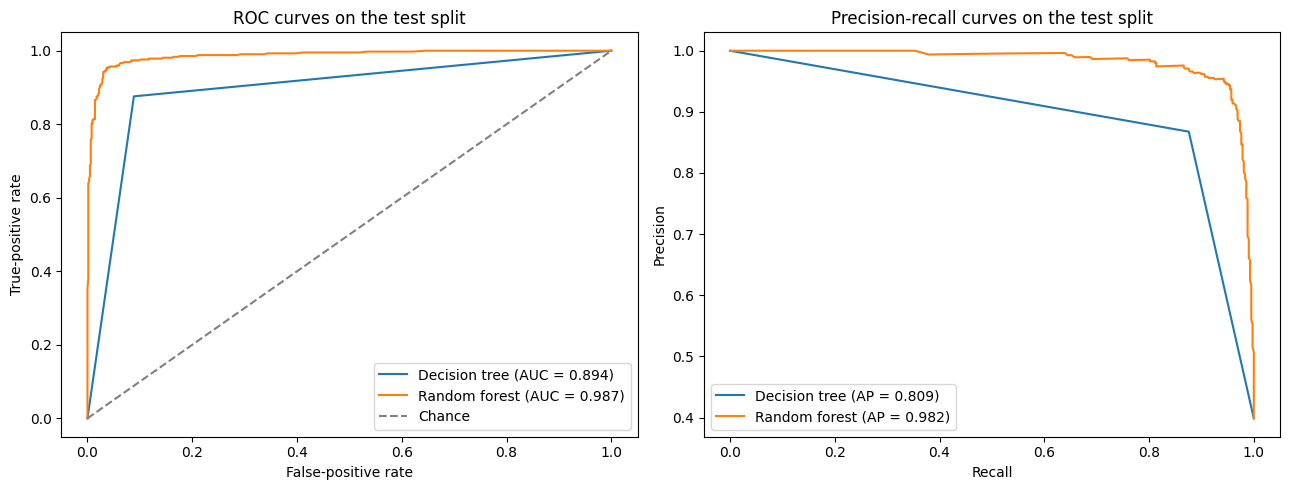

In [12]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_score,
    precision_recall_curve,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import cross_val_predict

tree.fit(X_train, y_train)
rf.fit(X_train, y_train)
tree_test_probability = tree.predict_proba(X_test)[:, 1]
rf_test_probability = rf.predict_proba(X_test)[:, 1]

tree_auc = roc_auc_score(y_test, tree_test_probability)
rf_auc = roc_auc_score(y_test, rf_test_probability)
tree_ap = average_precision_score(y_test, tree_test_probability)
rf_ap = average_precision_score(y_test, rf_test_probability)
print(f"Decision tree ROC AUC: {tree_auc:.4f}; average precision: {tree_ap:.4f}")
print(f"Random forest ROC AUC: {rf_auc:.4f}; average precision: {rf_ap:.4f}")

tree_fpr, tree_tpr, _ = roc_curve(y_test, tree_test_probability)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_test_probability)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(tree_fpr, tree_tpr, label=f"Decision tree (AUC = {tree_auc:.3f})")
axes[0].plot(rf_fpr, rf_tpr, label=f"Random forest (AUC = {rf_auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[0].set(title="ROC curves on the test split", xlabel="False-positive rate", ylabel="True-positive rate")
axes[0].legend(fontsize=10)

tree_precision, tree_recall, _ = precision_recall_curve(y_test, tree_test_probability)
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_test_probability)
axes[1].plot(tree_recall, tree_precision, label=f"Decision tree (AP = {tree_ap:.3f})")
axes[1].plot(rf_recall, rf_precision, label=f"Random forest (AP = {rf_ap:.3f})")
axes[1].set(title="Precision-recall curves on the test split", xlabel="Recall", ylabel="Precision")
axes[1].legend(fontsize=10)
for axis in axes:
    axis.tick_params(labelsize=10)
    axis.title.set_fontsize(12)
fig.tight_layout()
plt.show()

On the test split, the tree had ROC AUC **0.8936** and average precision **0.8094**; the forest had ROC AUC **0.9868** and average precision **0.9822**.

In [13]:
oof_probability = cross_val_predict(
    rf, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]
oof_fpr, oof_tpr, thresholds = roc_curve(
    y_train, oof_probability, drop_intermediate=False
)
eligible = np.flatnonzero(oof_fpr <= 0.01)
best_recall = oof_tpr[eligible].max()
best_candidates = eligible[oof_tpr[eligible] == best_recall]
threshold_index = best_candidates[np.argmax(thresholds[best_candidates])]
threshold = thresholds[threshold_index]
print(f"Threshold selected on training OOF probabilities: {threshold:.10f}")
print(f"Training OOF FPR at threshold: {oof_fpr[threshold_index]:.4f}")
print(f"Training OOF recall at threshold: {oof_tpr[threshold_index]:.4f}")

test_prediction_at_threshold = (rf_test_probability >= threshold).astype(int)
test_confusion = confusion_matrix(y_test, test_prediction_at_threshold, labels=[0, 1])
tn, fp, fn, tp = test_confusion.ravel()
test_precision = precision_score(y_test, test_prediction_at_threshold, zero_division=0)
test_recall = recall_score(y_test, test_prediction_at_threshold, zero_division=0)
test_fpr = fp / (fp + tn)
legitimate_test_count = fp + tn
test_fpr_se = np.sqrt(test_fpr * (1 - test_fpr) / legitimate_test_count)
print("Test confusion matrix (rows=true [0, 1], columns=predicted [0, 1]):")
print(test_confusion)
print(f"Test precision: {test_precision:.4f}")
print(f"Test recall: {test_recall:.4f}")
print(f"Test FPR: {test_fpr:.4f} +/- {test_fpr_se:.4f} (binomial standard error)")
print(f"Legitimate test emails flagged: {fp} out of {legitimate_test_count}")
print(f"The 1% FPR target held on test: {test_fpr <= 0.01}")

Threshold selected on training OOF probabilities: 0.7300000000
Training OOF FPR at threshold: 0.0095
Training OOF recall at threshold: 0.8178
Test confusion matrix (rows=true [0, 1], columns=predicted [0, 1]):
[[625   7]
 [ 79 340]]
Test precision: 0.9798
Test recall: 0.8115
Test FPR: 0.0111 +/- 0.0042 (binomial standard error)
Legitimate test emails flagged: 7 out of 632
The 1% FPR target held on test: False


The threshold was selected from training OOF probabilities only: `t = 0.73`, with OOF FPR 0.0095 and recall 0.8178. Applied once to test, the confusion matrix was `[[625, 7], [79, 340]]`; precision was 0.9798 and recall was 0.8115. The test FPR was 0.0111 (7 of 632 legitimate emails), with binomial SE 0.0042, so the 1% target did not hold on this test sample. The observed 1.11% FPR is just 0.11 percentage points above target, much smaller than its 0.42-point standard error; with only 632 legitimate test emails, the estimate has substantial sampling uncertainty.

In [14]:
permutation = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy"
)
permutation_importance_mean = pd.Series(permutation.importances_mean, index=X_train.columns)
impurity_importance = pd.Series(rf.feature_importances_, index=X_train.columns)
top_permutation = permutation_importance_mean.nlargest(5)
top_impurity = impurity_importance.nlargest(5)
importance_features = top_permutation.index.union(top_impurity.index)
importance_table = pd.DataFrame({
    "permutation_rank": permutation_importance_mean.rank(method="min", ascending=False).loc[importance_features].astype(int),
    "permutation_mean_accuracy_drop": permutation_importance_mean.loc[importance_features],
    "impurity_rank": impurity_importance.rank(method="min", ascending=False).loc[importance_features].astype(int),
    "impurity_importance": impurity_importance.loc[importance_features],
}).sort_values(["permutation_rank", "impurity_rank"])
print("Union of the top five features from each importance ranking:")
display(importance_table.round(5))

Union of the top five features from each importance ranking:


,permutation_rank,permutation_mean_accuracy_drop,impurity_rank,impurity_importance
word_freq_remove,1,0.03501,2,0.08783
word_freq_hp,2,0.02160,8,0.05074
char_freq_exclam,3,0.01912,1,0.11342
capital_run_length_average,4,0.01389,4,0.06761
word_freq_george,5,0.00980,13,0.02325
word_freq_free,6,0.00761,5,0.06402
char_freq_dollar,7,0.00742,3,0.08751


The union table includes the top five features from each ranking. `word_freq_george` ranks 5th by permutation importance but 13th by impurity importance: shuffling it reduces held-out accuracy by 0.00980, while the forest's accumulated training split importance is 0.02325. These measures differ because permutation importance measures held-out predictive reliance, whereas impurity importance sums training split improvements; correlated predictors can also share or substitute for predictive information.

## Part 3

We implement the handout's weighted majority vote, check it against scikit-learn hard voting, and compare individual members with hard and soft voting on the same cross-validation folds.

In [15]:
def hard_vote(predictions, weights=None):
    """Return the weighted majority class for each sample, breaking ties low."""
    predictions = np.asarray(predictions, dtype=int)
    n_models, n_samples = predictions.shape
    if weights is None:
        weights = np.ones(n_models, dtype=float)
    else:
        weights = np.asarray(weights)

    result = np.zeros(n_samples, dtype=int)
    for sample_index in range(n_samples):
        labels = np.unique(np.append(predictions[:, sample_index], 0))
        best_label = labels[0]
        best_count = 0
        for label in labels:
            count = 0
            for model_index in range(n_models):
                if predictions[model_index, sample_index] == label:
                    count += weights[model_index]
            if count > best_count:
                best_label = label
                best_count = count
        result[sample_index] = best_label
    return result

In [16]:
vote_examples = [
    (hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]), [0, 1, 0]),
    (hard_vote([[0, 1], [1, 0]]), [0, 0]),
    (hard_vote([[0, 1], [1, 0]], weights=[1, 2]), [1, 0]),
    (hard_vote([[2, 0], [2, 1], [0, 1]]), [2, 1]),
    (hard_vote([[1], [2]], weights=[0, 0]), [0]),
]
for number, (actual, expected) in enumerate(vote_examples, start=1):
    print(f"Example {number}: {actual}; matches expected: {np.array_equal(actual, expected)}")

Example 1: [0 1 0]; matches expected: True
Example 2: [0 0]; matches expected: True
Example 3: [1 0]; matches expected: True
Example 4: [2 1]; matches expected: True
Example 5: [0]; matches expected: True


The implementation follows model order when accumulating weights and uses strict comparisons, so exact ties go to the smallest label; when every weight is zero, label 0 wins. All handout examples, including labels above 1 and the all-zero-weight case, are checked above.

In [17]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

member_test_predictions = np.array([
    clone(model).fit(X_train, y_train).predict(X_test)
    for _, model in members
])
own_hard_predictions = hard_vote(member_test_predictions)
hard_voter = VotingClassifier(members, voting="hard").fit(X_train, y_train)
sklearn_hard_predictions = hard_voter.predict(X_test)
hard_predictions_equal = np.array_equal(own_hard_predictions, sklearn_hard_predictions)
agreement_fraction = np.mean(own_hard_predictions == sklearn_hard_predictions)
print("Own hard_vote equals VotingClassifier predictions:", hard_predictions_equal)
print(f"Fraction of matching test predictions: {agreement_fraction:.4f}")

disagreements = []
for first in range(len(members)):
    for second in range(first + 1, len(members)):
        disagreements.append({
            "member_1": members[first][0],
            "member_2": members[second][0],
            "disagreement_rate": np.mean(member_test_predictions[first] != member_test_predictions[second]),
        })
disagreement_table = pd.DataFrame(disagreements)
display(disagreement_table.round(4))

Own hard_vote equals VotingClassifier predictions: True
Fraction of matching test predictions: 1.0000


,member_1,member_2,disagreement_rate
0,lr,knn,0.0485
1,lr,tree,0.1028
2,knn,tree,0.1265


The own `hard_vote` exactly reproduced `VotingClassifier(voting="hard")` on the test split (`True`; matching fraction 1.0000). Test disagreement rates were 0.0485 for LR vs KNN, 0.1028 for LR vs tree, and 0.1265 for KNN vs tree.

In [18]:
hard_voting = VotingClassifier(members, voting="hard")
soft_voting = VotingClassifier(members, voting="soft")
voting_models = {"lr": lr, "knn": knn, "tree": tree,
                 "hard voting": hard_voting, "soft voting": soft_voting}
voting_fold_scores = {
    name: cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    for name, model in voting_models.items()
}
voting_cv_table = pd.DataFrame(
    {name: scores for name, scores in voting_fold_scores.items()},
    index=[f"fold_{i}" for i in range(1, cv.get_n_splits() + 1)],
).T
voting_cv_table["mean"] = [voting_fold_scores[name].mean() for name in voting_cv_table.index]
voting_cv_table["std"] = [voting_fold_scores[name].std() for name in voting_cv_table.index]
display(voting_cv_table.round(4))

member_means = {name: voting_fold_scores[name].mean() for name in ("lr", "knn", "tree")}
best_member = max(member_means, key=member_means.get)
print(f"Best single member by CV mean: {best_member} ({member_means[best_member]:.4f})")
paired_voting_differences = {}
for voter_name in ("hard voting", "soft voting"):
    differences = voting_fold_scores[voter_name] - voting_fold_scores[best_member]
    paired_voting_differences[voter_name] = differences
    judgement = "no winner / inside the noise" if abs(differences.mean()) <= differences.std() else (
        "voting is higher outside the fold spread" if differences.mean() > 0 else
        "best member is higher outside the fold spread"
    )
    print(f"{voter_name} - {best_member}: fold differences={np.round(differences, 4)}; "
          f"mean={differences.mean():.4f}, std={differences.std():.4f}; {judgement}.")

,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
lr,0.9319,0.9192,0.9303,0.9413,0.9508,0.9347,0.0107
knn,0.9113,0.9081,0.9208,0.9413,0.9063,0.9175,0.0129
tree,0.8906,0.8891,0.9017,0.9175,0.9095,0.9017,0.0109
hard voting,0.9319,0.9239,0.9398,0.9603,0.9460,0.9404,0.0124
soft voting,0.9350,0.9287,0.9319,0.9603,0.9460,0.9404,0.0116


Best single member by CV mean: lr (0.9347)
hard voting - lr: fold differences=[ 0.      0.0048  0.0095  0.019  -0.0048]; mean=0.0057, std=0.0082; no winner / inside the noise.
soft voting - lr: fold differences=[ 0.0032  0.0095  0.0016  0.019  -0.0048]; mean=0.0057, std=0.0081; no winner / inside the noise.


The best single member was LR (CV mean 0.9347). Hard voting's CV mean was 0.9404 and its paired difference from LR was `[0.0000, 0.0048, 0.0095, 0.0190, -0.0048]`, with mean 0.0057 and std 0.0082. Soft voting's CV mean was also 0.9404; its paired differences were `[0.0032, 0.0095, 0.0016, 0.0190, -0.0048]`, with mean 0.0057 and std 0.0081. For both ensembles, the mean gain is smaller than the paired-difference spread, so there is no winner / the differences are inside the noise.